# The IRRBB validation tests: golden shocks, sum of parts, parameter stability and the change at a limit breach

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- name the seven IRRBB validation tests of the engine, what each one tests, and the rule that gives its light;
- run each test on the inputs the committed documents hold and obtain the committed row, down to the hash of its inputs where the document stores them whole;
- show that a test is not vacuous by changing one input and watching its light change;
- read the stability of the replicating-portfolio weights across estimation windows and explain why it is the weakest result of the case;
- say what the tests state and what they do not: they are internal gates of Contraste, not regulatory thresholds.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14 (the interest rate risk in the banking book of the bank that failed in March 2023) at three valuation dates, 2021-Q4, 2022-Q2 and 2022-Q4, and case C15 (the synthetic Banco Andino on a CLP and UF balance sheet) for the Chilean test. C14 uses the FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates); C15 uses the CMF aggregates of August 2026 and the curves of the Banco Central de Chile (series F022); all four are public sources of the licence class `mirror-allowed`. C14 is real in aggregate and synthetic in behaviour; C15 is a synthetic bank on real curves.

- **Files read:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`; `tests`, the six rows) and `models-svb-2021-2022.json` (`fit.nmd_models`, the replicating weights by window), and `data/derived/C15/short-uf.json` (`tests`, the Annex 1 goldens).

The next cell loads the files.

In [2]:
# Load the three valuation dates of C14, the model document and the C15 variant (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
c15 = json.loads((ROOT / "data" / "derived" / "C15" / "short-uf.json").read_text(encoding="utf-8"))
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {True: "yes", False: "no"}

def row_of(document, test_id):
    return next(row for row in document["tests"] if row["test_id"] == test_id)

for q, d in docs.items():
    print(q, "| baked by riskvalidation", d["provenance"]["riskvalidation_version"], "| installed", rv.__version__, "| test rows", len(d["tests"]))
print("C15 | baked by riskvalidation", c15["provenance"]["riskvalidation_version"], "| test rows", len(c15["tests"]))

2021-Q4 | baked by riskvalidation 0.9.0 | installed 0.9.0 | test rows 6
2022-Q2 | baked by riskvalidation 0.9.0 | installed 0.9.0 | test rows 6
2022-Q4 | baked by riskvalidation 0.9.0 | installed 0.9.0 | test rows 6
C15 | baked by riskvalidation 0.9.0 | test rows 5


## Method

The engine holds seven IRRBB validation tests in `riskvalidation.validation.irrbb`. Each is a plain function that returns one `TestResult` and states its light rule in its docstring. They follow the lessons that the research turned into tests (dossier 05, D.7): an implementation must reproduce the standard's own examples, its parts must add up to the whole, a behavioural parameter must be stable, the behavioural layer must be reported beside the contractual reading, a change in a behavioural assumption must not coincide with a breach, and a projection must be compared with what happened.

| Test | What it tests | Rule of the light |
|---|---|---|
| `irrbb.srp31_92_goldens` | the worked example of the standard | green if every value is within its tolerance |
| `irrbb.cmf_annex1_goldens` | the Chilean Annex 1 formulas and table | green if all 19 cases are exact |
| `irrbb.eve_sum_of_parts` | EVE of the whole equals the sum of its items | green if the relative residual is at most `rel_tol` |
| `irrbb.nmd_parameter_stability` | replicating weights across windows | green, amber, red by the sup-norm distance |
| `irrbb.eve_with_without_behavioural` | the two readings together | green, amber, red; red if a breach is hidden |
| `irrbb.behavioural_change_at_breach` | a change that coincides with a breach | red if any |
| `irrbb.nii_out_of_sample` | projection against the realised change | green, amber, red by the relative error |

The gates are **Contraste internal gates**, stated as such in each docstring and recorded in the result's `policy_version` and `extras["thresholds"]`; none states a compliance claim. A test that cannot be evaluated returns the light `not_evaluated` with the reason in `notes`, never a made-up number.

### Step 1: the two golden tests

A golden test recomputes a value the primary source prints and compares it with the print. `irrbb.srp31_92_goldens` was read in notebook 02 (the four values of the worked example at 3.5 years). `irrbb.cmf_annex1_goldens` checks 19 cases of the Chilean Annex 1: the offset table `cmf_pair` on both signs (8 cases), the table of shock sizes (5 rows), the indexation charge, the `annex1_delta_eve` example (3 cases) and the worked example of Annex 1 (2 cases). Its statistic is the number of failed cases, and an exception counts as a failed case. The next cell runs both and compares them with the committed rows.

In [3]:
# Run both golden tests and compare them with the committed rows of C14 and C15
for run, source, label in ((rv_irrbb.srp31_92_goldens(), docs["2022-Q2"], "C14"), (rv_irrbb.cmf_annex1_goldens(), c15, "C15")):
    row = row_of(source, run.test_id)
    print(f"{run.test_id}: light {run.light.value} | statistic {run.statistic:.4f} | n = {run.n} | failed cases {run.extras.get('failed', '-')}")
    print(f"    {label}: committed row {row['light']} {row['statistic']:.4f} n = {row['n']} | equal {NAME[bool(row['light'] == run.light.value and np.isclose(row['statistic'], run.statistic) and row['n'] == run.n)]}")

irrbb.srp31_92_goldens: light green | statistic 0.0393 | n = 4 | failed cases -
    C14: committed row green 0.0393 n = 4 | equal yes
irrbb.cmf_annex1_goldens: light green | statistic 0.0000 | n = 19 | failed cases []
    C15: committed row green 0.0000 n = 19 | equal yes


### Step 2: the sum of parts

The EVE is linear in the cash flows, $EVE(x) = \sum_k x_k\, DF_k$, so the EVE of the whole balance sheet must equal the sum of the EVEs of its items. The test `irrbb.eve_sum_of_parts` computes the EVE of each item row and adds them, compares with the EVE of the aggregated flows the pipeline reported, and takes the relative residual $|\sum_i EVE_i - EVE_{whole}| / |EVE_{whole}|$; it is green at most `rel_tol = 1e-9`. The 17 item vectors are in the committed balance sheet, and the base EVE is the one of the first scenario. The next cell runs it at the three dates and compares each row with the committed one, on the light, the statistic and the relative residual. The hash of the inputs, the engine's fingerprint of exactly what was tested, is not compared for this test: it depends on the exact bytes of the arrays the pipeline passed, and the document stores only the non-zero buckets of each item, so the rebuilt array is not guaranteed to be bit-identical. The tests of the next steps take their inputs whole from the document, and their hash is compared.

In [4]:
# Run the sum-of-parts test at the three dates with the 17 item vectors and compare with the committed rows
inputs = {}
for q, d in docs.items():
    o = d["outputs"]
    r0 = np.array(o["curve"]["zero_rates_at_midpoints"])
    item_flows = np.zeros((len(o["balance_sheet"]["items"]), 19))
    for i, item in enumerate(o["balance_sheet"]["items"]):
        for flow in item["cash_flows"]["behavioural"]:
            item_flows[i, flow["bucket"] - 1] += flow["amount"]
    whole = o["scenarios"][0]["base_eve"]
    inputs[q] = (item_flows, r0, whole)
    run = rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole)
    row = row_of(d, run.test_id)
    print(f"{q}: items {run.n} | sum of the parts {run.extras['sum_of_parts']:,.3f} | whole {run.extras['whole_eve']:,.3f} | relative residual {run.metric:.2e} | light {run.light.value}")
    print(f"    equal to the committed row (light, statistic, relative residual): {NAME[bool(row['light'] == run.light.value and np.isclose(row['statistic'], run.statistic) and np.isclose(row['metric'], run.metric))]}")

2021-Q4: items 17 | sum of the parts 8,982,670.014 | whole 8,982,670.014 | relative residual 2.07e-16 | light green
    equal to the committed row (light, statistic, relative residual): yes
2022-Q2: items 17 | sum of the parts 7,036,780.156 | whole 7,036,780.156 | relative residual 1.06e-15 | light green
    equal to the committed row (light, statistic, relative residual): yes
2022-Q4: items 17 | sum of the parts 5,257,967.562 | whole 5,257,967.562 | relative residual 2.48e-15 | light green
    equal to the committed row (light, statistic, relative residual): yes


A test that always passes is worth nothing, so the next cell changes one input and watches the light. First, the whole EVE is shifted by one unit (one thousand dollars, a relative change of about $10^{-7}$): the gate of $10^{-9}$ turns it red. Second, the same shift under a looser gate, `rel_tol = 1e-6`, stays green. Third, one item is left out of the item rows while the whole keeps it, which is the error the test exists to catch.

In [5]:
# Negative controls on 2022-Q2: shift the whole by one unit, loosen the gate, and leave one item out
item_flows, r0, whole = inputs["2022-Q2"]
for label, run in (
    ("whole + 1, gate 1e-9", rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0)),
    ("whole + 1, gate 1e-6", rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0, rel_tol=1e-6)),
    ("one item left out", rv_irrbb.eve_sum_of_parts(item_flows[1:], r0, MID, whole)),
):
    print(f"{label:34s} relative residual {run.metric:.2e} | light {run.light.value}")

whole + 1, gate 1e-9               relative residual 1.42e-07 | light red
whole + 1, gate 1e-6               relative residual 1.42e-07 | light green
one item left out                  relative residual 2.03e+00 | light red


### Step 3: the stability of the replicating weights

Notebook 03 showed that the replicating-portfolio weights are an estimate with a flat objective. `irrbb.nmd_parameter_stability` measures how much they move when the estimation window moves (dossier 05, D.3; BCBS d368). The pipeline re-estimates the weights on three windows of 16 quarters ending at the valuation date, one year before and two years before. The statistic is the largest sup-norm distance between the weights of consecutive windows, $\max_j |w_{a,j} - w_{b,j}|$; the metric is the largest change of the weighted average maturity between consecutive windows, in years. The light is green at most 0.10, amber at most 0.25, red above. The next cell runs it from the committed weights of each date and prints the weights, the maturities and the distances.

In [6]:
# Run the stability test on the three windows of each date and compare with the committed rows, hash included
windows = {}
for q, d in docs.items():
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == d["outputs"]["valuation_date"])
    weights = np.array([w["weights"] for w in model["stability"]])
    maturities = np.array([t["maturity_years"] for t in model["tranches"]])
    run = rv_irrbb.nmd_parameter_stability(weights, maturities)
    windows[q] = (model, run)
    row = row_of(d, run.test_id)
    print(f"{q}: windows ending {[w['window_end'] for w in model['stability']]}")
    print(f"    weight on the 10-year tranche by window {[round(float(w[-1]), 3) for w in weights]} | average maturity (y) {[round(x, 3) for x in run.extras['weighted_average_maturity']]}")
    print(f"    distances {[round(x, 3) for x in run.extras['distances']]} | statistic {run.statistic:.4f} | maturity change (y) {run.metric:.4f} | light {run.light.value}")
    print(f"    equal to the committed row (hash included): {NAME[bool(row['light'] == run.light.value and np.isclose(row['statistic'], run.statistic) and row['inputs_hash'] == run.inputs_hash)]}")

2021-Q4: windows ending ['2019-12-31', '2020-12-31', '2021-12-31']
    weight on the 10-year tranche by window [0.794, 0.426, 0.951] | average maturity (y) [3.995, 2.204, 4.759]
    distances [0.367, 0.524] | statistic 0.5243 | maturity change (y) 2.5559 | light red
    equal to the committed row (hash included): yes
2022-Q2: windows ending ['2020-06-30', '2021-06-30', '2022-06-30']
    weight on the 10-year tranche by window [0.544, 0.74, 0.837] | average maturity (y) [2.775, 3.734, 4.205]
    distances [0.197, 0.097] | statistic 0.1967 | maturity change (y) 0.9588 | light amber
    equal to the committed row (hash included): yes
2022-Q4: windows ending ['2020-12-31', '2021-12-31', '2022-12-31']
    weight on the 10-year tranche by window [0.426, 0.951, 1.0] | average maturity (y) [2.204, 4.759, 5.0]
    distances [0.524, 0.049] | statistic 0.5243 | maturity change (y) 2.5559 | light red
    equal to the committed row (hash included): yes


### Step 4: the two readings of the EVE together

`irrbb.eve_with_without_behavioural` was built in notebook 03 from the two EVE risk measures: it is green at most 0.05 of Tier 1, amber at most 0.15, red above, and red whatever the size if the behavioural measure passes the 15 percent line and the contractual one breaches it. Here the next cell only takes the two measures of the committed scenarios (2024 calibration) at each date, runs the test and compares it with the committed row, hash included.

In [7]:
# Run the with-and-without test from the two committed measures of each date and compare with the committed row
for q, d in docs.items():
    blocks = {b["nmd_assumption"]: b for b in d["outputs"]["scenarios"] if b["calibration"] == "2024"}
    tier1 = blocks["behavioural"]["outlier"]["tier1"]
    run = rv_irrbb.eve_with_without_behavioural(blocks["behavioural"]["eve_risk_measure"], blocks["contractual"]["eve_risk_measure"], tier1)
    row = row_of(d, run.test_id)
    print(f"{q}: Tier 1 {tier1:,.0f} | statistic {run.statistic:.4f} | light {run.light.value} | hidden breach {NAME[run.extras['hidden_breach']]} | equal to the committed row (hash included) {NAME[bool(row['light'] == run.light.value and row['inputs_hash'] == run.inputs_hash)]}")

2021-Q4: Tier 1 14,622,000 | statistic 0.7222 | light red | hidden breach no | equal to the committed row (hash included) yes
2022-Q2: Tier 1 16,349,000 | statistic 0.5623 | light red | hidden breach no | equal to the committed row (hash included) yes
2022-Q4: Tier 1 16,995,000 | statistic 0.4655 | light red | hidden breach no | equal to the committed row (hash included) yes


### Step 5: the change at a limit breach

The Federal Reserve's review of Silicon Valley Bank found that the bank "made counterintuitive modeling assumptions about the duration of deposits to address the limit breach rather than managing the actual risk" (Board of Governors of the Federal Reserve System, 2023, https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). `irrbb.behavioural_change_at_breach` turns that into a test: given a series of values of a behavioural parameter on increasing dates and a flag per date that says whether a limit was breached in the window ending there, it counts the dates where the value changed ($v_t \ne v_{t-1}$) and the flag is true. The statistic is that count; the light is red when it is at least one, green when it is zero, `not_evaluated` with fewer than two dates. In C14 the parameter is the weighted average maturity of the fitted replicating portfolio of the wholesale deposits, and the flag is the standardised outlier test of the date. The next cell builds the history up to each date from the committed values and runs the engine, and compares each result with the committed row. Notebook 08 examines what the test does and does not discriminate.

In [8]:
# Build the history of the average maturity and of the breach flag up to each date, run the engine and compare with the committed row
dates = [d["outputs"]["valuation_date"] for d in docs.values()]
values = [next(m for m in fit["nmd_models"] if m["valuation_date"] == day)["weighted_average_maturity_years"] for day in dates]
breach = [bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()]
print("dates:", dates)
print("average maturity (y):", [round(v, 4) for v in values], "| breach flag:", [NAME[b] for b in breach])
for k, (q, d) in enumerate(docs.items(), start=1):
    run = rv_irrbb.behavioural_change_at_breach(np.array(values[:k]), np.array(dates[:k], dtype="datetime64[D]"), np.array(breach[:k], dtype=bool))
    row = row_of(d, run.test_id)
    print(f"{q}: dates {run.n} | light {run.light.value} | flagged changes {run.extras.get('flagged_dates', [])} | {run.notes}")
    print(f"    equal to the committed row (hash included): {NAME[bool(row['light'] == run.light.value and row['inputs_hash'] == run.inputs_hash)]}")

dates: ['2021-12-31', '2022-06-30', '2022-12-31']
average maturity (y): [4.7595, 4.2049, 5.0] | breach flag: ['yes', 'yes', 'yes']
2021-Q4: dates 1 | light not_evaluated | flagged changes [] | not evaluated: fewer than 2 dates
    equal to the committed row (hash included): yes
2022-Q2: dates 2 | light red | flagged changes ['2022-06-30'] | 1 change(s) coincide with a breach
    equal to the committed row (hash included): yes
2022-Q4: dates 3 | light red | flagged changes ['2022-06-30', '2022-12-31'] | 2 change(s) coincide with a breach
    equal to the committed row (hash included): yes


### Step 6: the out-of-sample projection

`irrbb.nii_out_of_sample` was run in notebook 04 on the 2021-Q4 projection (a relative error of 16.2 percent, amber). The other two dates have no realised year. The next cell reads the three committed rows and prints the light of each, then prints, for the three dates, every committed test with its light, so the whole battery of the case is on one table.

In [9]:
# The committed battery of C14 at the three dates and the committed rows of C15, one light per test
print(f"{'test_id':38s} " + " ".join(f"{q:>14s}" for q in docs))
for test_id in [row["test_id"] for row in docs["2022-Q2"]["tests"]]:
    print(f"{test_id:38s} " + " ".join(f"{row_of(d, test_id)['light']:>14s}" for d in docs.values()))
print("C15:", [(row["test_id"], row.get("segment"), row["light"]) for row in c15["tests"]])

test_id                                       2021-Q4        2022-Q2        2022-Q4
irrbb.srp31_92_goldens                          green          green          green
irrbb.eve_sum_of_parts                          green          green          green
irrbb.eve_with_without_behavioural                red            red            red
irrbb.nmd_parameter_stability                     red          amber            red
irrbb.behavioural_change_at_breach      not_evaluated            red            red
irrbb.nii_out_of_sample                         amber  not_evaluated  not_evaluated
C15: [('irrbb.srp31_92_goldens', None, 'green'), ('irrbb.cmf_annex1_goldens', None, 'green'), ('irrbb.eve_sum_of_parts', 'CLP', 'green'), ('irrbb.eve_sum_of_parts', 'UR', 'green'), ('irrbb.nmd_parameter_stability', 'wholesale', 'not_evaluated')]


The last cell draws the weighted average maturity of the three estimation windows of each date (left), and the relative residual of the sum-of-parts test against its gate (right). On the left the lines do not agree: the same quarters, estimated with a window one year earlier, give a different average maturity, and the swings are wider than the gate allows. On the right the residuals are six to seven orders of magnitude under the gate, the numerical noise of adding floats, which is why the gate can be so tight.

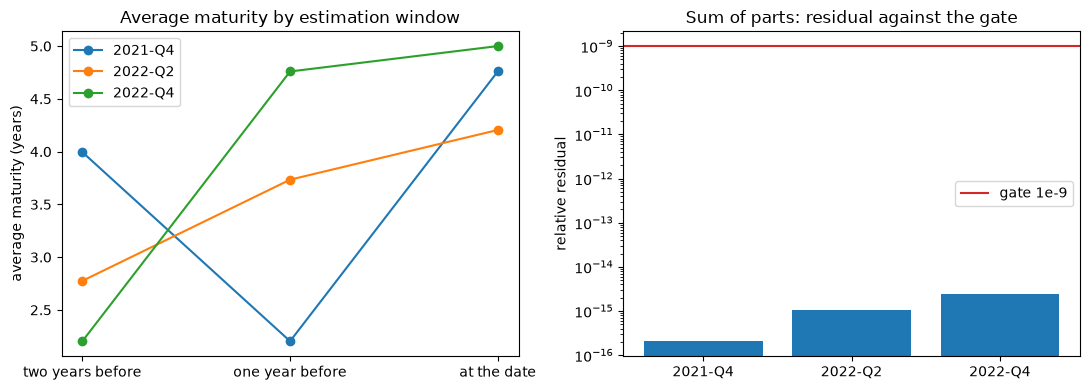

In [10]:
# Draw the average maturity by estimation window and the relative residual of the sum of parts
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for q, (model, run) in windows.items():
    left.plot([1, 2, 3], run.extras["weighted_average_maturity"], marker="o", label=q)
left.set_xticks([1, 2, 3])
left.set_xticklabels(["two years before", "one year before", "at the date"])
left.set_ylabel("average maturity (years)")
left.set_title("Average maturity by estimation window")
left.legend()
residuals = [row_of(d, "irrbb.eve_sum_of_parts")["metric"] for d in docs.values()]
right.bar(list(docs), [max(r, 1e-18) for r in residuals], color="tab:blue")
right.axhline(1e-9, color="tab:red", label="gate 1e-9")
right.set_yscale("log")
right.set_ylabel("relative residual")
right.set_title("Sum of parts: residual against the gate")
right.legend()
fig.tight_layout()
plt.show()

## Results

- **The goldens.** Both golden tests are green and equal to their committed rows: the worked example of the standard has a statistic of 0.0393 (the flattener, at the printed precision) and the Chilean Annex 1 passes 19 of 19 cases with none failed. They say that the implementation reproduces what the sources print; they do not say that the sources are applied correctly to a balance sheet.
- **The sum of parts.** The relative residual is of the order of 10^-15 at the three dates, six orders of magnitude under the gate of 10^-9, and the rows are equal to the committed ones. The controls show the test is alive: a shift of one unit in the whole (a relative change of 1.4 x 10^-7) turns it red under the gate of 10^-9 and leaves it green under a gate of 10^-6, so the gate decides what the test can see; leaving one item out gives a relative residual of 2.03 and red. The test cannot see an error that is present in both the items and the whole.
- **The stability of the weights.** The average maturity of the wholesale deposits depends on the window it is estimated on. At 2021-Q4 the three windows give 3.995, 2.204 and 4.759 years, a swing of 2.56 years between consecutive windows, and the light is red; at 2022-Q4 the windows give 2.204, 4.759 and 5.000 years, red again; only 2022-Q2, with 2.775, 3.734 and 4.205 years, is amber, with a distance of 0.197 between weights. The value the bank would report is the one of the last window, so the window is a lever: a longer window or a different end date moves the deposit maturity by years. This is the weakest result of the case, and it is the one a validator should put first.
- **The two readings of the EVE.** The with-and-without test is red at the three dates, with statistics of 0.722, 0.562 and 0.466 of Tier 1 and no hidden breach: the behavioural measure and the contractual one are on the same side of the 15 percent line, but far apart. The committed rows are equal, hash included.
- **The change at a breach.** The weighted average maturity is 4.7595, 4.2049 and 5.0 years at the three dates and the standardised outlier test is breached at all three. The test is not evaluated at the first date (one date), red at the second (one change coincides with a breach, at 2022-06-30) and red at the third (two changes, at 2022-06-30 and 2022-12-31). The rows are equal, hash included. Two cautions: every date is in breach, and the parameter is a fitted one that is re-estimated at each date, so it moves by construction; the red says that the pattern is present, not that anyone chose the number to relieve a breach. Notebook 08 takes this apart.
- **The out-of-sample test.** Amber at 2021-Q4 (16.2 percent) and `not_evaluated` at the other two dates, where the bank filed no later report. The whole battery therefore reads: goldens and sum of parts green, the with-and-without test red, the stability red or amber, the change at a breach red where it can be evaluated, and the projection amber where it can be compared. In the synthetic bank of C15 the same functions give green for the goldens and the sum of parts of both currencies, and `not_evaluated` for the stability, because it has a single estimation window.
- **What the tests state.** The gates are Contraste internal gates, not regulatory thresholds: a red is a finding to read, not a failed compliance. What they do not show is whether a green balance sheet is right; they show that it is internally consistent.

## Summary

- The engine holds seven IRRBB validation tests; each one is a function that returns a `TestResult`, states its light rule, and records its thresholds as Contraste internal gates, never as regulation.
- Every committed row is reproduced from the committed inputs; where the document stores the inputs whole, the hash of the inputs matches too, which is the proof that the row is exactly what was tested.
- A test is shown not to be vacuous by changing one input: a one-unit shift of the whole turns the sum of parts red, a looser gate turns it green, and a missing item turns it red.
- The stability of the replicating weights is the weakest result: red at two of three dates, with swings of the average maturity above two years between windows.
- The test that flags a behavioural change at a breach is red at two dates, and the next steps (notebook 08) examine what that does and does not mean; the out-of-sample test is evaluated at one date only, because the bank filed no later report.

**What to try next.** Change `gap_amber` and `gap_red` in `nmd_parameter_stability` and see which dates change colour. Then continue with notebook 06, the Chilean Annex 1.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 to SRP31.92 (the worked example), SRP31.82 to SRP31.83 and SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book (the replicating portfolio and the stability of its weights). https://www.bis.org/bcbs/publ/d368.htm
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1 (the Chilean formulas and tables), as transcribed in dossier 03, F.2, and in the engine's golden test.
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research, sections D.3 and D.7.